In [83]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

# Chapter 4: Covariance Functions

## Question 2

Here we draw samples in 1D and 2D from the neural network covariance function given by

$$
k_\mathrm{NN}(\mathbf{x}, \mathbf{x}') = \frac{2}{\pi} \sin^{-1}\left(
    \frac{2 \tilde{\mathrm{x}}^\top \Sigma \tilde{\mathrm{x}}'}{\sqrt{(1 + 2 \tilde{\mathrm{x}}^\top \Sigma \tilde{\mathrm{x}})(1 + 2 \tilde{\mathrm{x}}'^\top \Sigma \tilde{\mathrm{x}}')}}
\right),
$$

where $\tilde{\mathrm{x}} = [1, \mathrm{x}^\top]^T$ is the augmented input vector.

In [84]:
def m(x):
    return np.zeros_like(x)

def gram_matrix(X1_tilde, X2_tilde = None, S = None):
    if S is None:
        S = 4 * np.eye(X1_tilde.shape[1])
    if X2_tilde is None:
        X2_tilde = X1_tilde
    X1_tilde = np.asarray(X1_tilde)
    X2_tilde = np.asarray(X2_tilde)

    num = 2 * X1_tilde @ S @ X2_tilde.T # num[i, j] = 2 x_i.T @ S @ x_j
    quad1 = 1 + 2 * np.einsum(
        "ni,ij,nj->n", X1_tilde, S, X1_tilde
    )
    quad2 = 1 + 2 * np.einsum(
        "ni,ij,nj->n", X2_tilde, S, X2_tilde
    )
    denom = np.sqrt(quad1[:, None] * quad2[None, :])
    frac = np.clip(num/denom, -1., 1.)
    return (2/np.pi) * np.arcsin(frac)
    

In [85]:
# 1D case
x = np.linspace(-10, 10, 100) # X
x_tilde = np.stack([np.ones_like(x), x], axis = -1) # X*2

mean = m(x_tilde[:, 0]) # X
cov = gram_matrix(x_tilde)

print(mean)
print(cov.shape)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]
(100, 100)


Text(0, 0.5, 'f(x)')

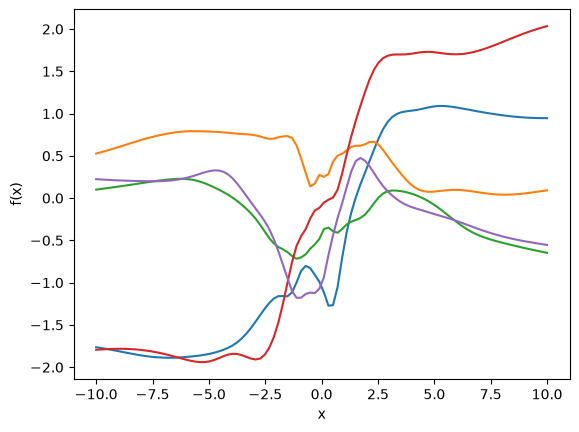

In [86]:
samples_1d = np.random.multivariate_normal(mean, cov, size = 5)

fig, ax = plt.subplots(1, 1)
ax.plot(x, samples_1d.T)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")

In [87]:
# 2D case
x = np.linspace(-10, 10, 50)
y = np.linspace(-10, 10, 50)
X, Y = np.meshgrid(x, y)
xy = np.stack([np.ones_like(X.ravel()), X.ravel(), Y.ravel()], axis = -1) # XY, 2

mean = m(xy[:, 0]) # XY
cov = gram_matrix(xy)
print(mean.shape)
print(cov.shape)


(2500,)
(2500, 2500)


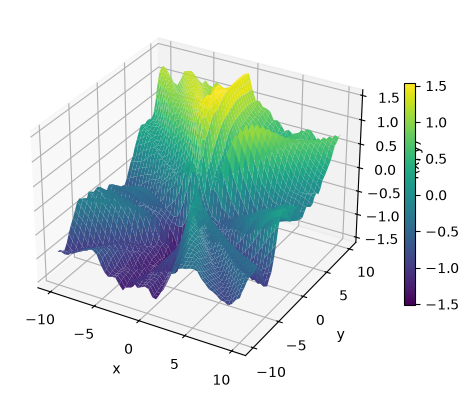

In [88]:
samples_2d = np.random.multivariate_normal(mean, cov).reshape(X.shape)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
surface = ax.plot_surface(X, Y, samples_2d, cmap="viridis")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x, y)")
fig.colorbar(surface, ax=ax, shrink=0.6)


## Question 3

Here we sample $\mathbf{u} \sim \mathcal{N}(\mathbf{0}, \Sigma)$ and apply the non-linear transform given below,

$$
f(\mathbf{x}) = \mathrm{erf}(u_0 + \sum_{i = 1}^D u_i x_i) = \mathrm{erf}(\tilde{\mathbf{x}}^\top \mathbf{u}).
$$

It should generate similar examples to the above Gaussian Process.

In [89]:
# 1D case
u_mean = np.zeros(2)
u_cov = 4 * np.eye(2)

x = np.linspace(-10, 10, 100) # X
x_tilde = np.stack([np.ones_like(x), x], axis = -1) # X*2

Text(0, 0.5, 'f(x)')

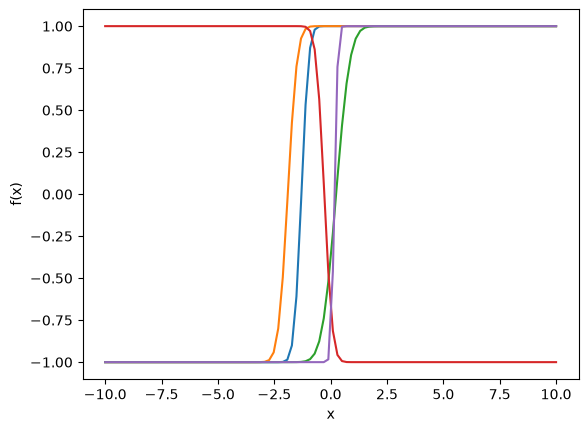

In [90]:
u_samples = np.random.multivariate_normal(u_mean, u_cov, size = 5)
dot = x_tilde @ u_samples.T

f = scipy.special.erf(dot)

fig, ax = plt.subplots(1, 1)
ax.plot(x, f)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")

Smooth samples suggest that even though the covariance function is the same, the non-Gaussian process sampling yields differing curves. In particular these curves are single sigmoids, whereas the neural network Gaussian process gives superposed sigmoids.

In effect, this is one random neuron, not infinite.

## Question 5

The Gibb's non-stationary covariance function is given by

$$
k(\mathbf{x}, \mathbf{x}') = \prod_{d=1}^D \left(
    \frac{2l_d(\mathbf{x})l_d(\mathbf{x}')}{l_d^2(\mathbf{x}) + l_d^2(\mathbf{x}')}
\right)^{1/2} \exp\left(
    -\sum_{d = 1}^D \frac{(x_d - x_d')^2}{l_d^2(\mathbf{x}) + l_d^2(\mathbf{x}')}
\right),
$$

where $l_d(\mathbf{x})$ is the length-scale in the $d$-th dimension at position $\mathbf{x} \in \mathbb{R}^D$.

In [91]:
def l(x):
    lengths = np.ones_like(x)
    lengths[..., 0] = 1 / (1 + np.exp(-x[..., 0])) # Sigmoid lengthscales for the first dimension.
    return lengths # X * D

def m_gibbs(x):
    return np.zeros_like(x)

def gram_matrix_gibbs(l, X1, X2 = None):
    if X2 is None:
        X2 = X1
    X1 = np.asarray(X1)
    X2 = np.asarray(X2)

    l1 = l(X1)[:, None, :] # X1 * 1 * D
    l2 = l(X2)[None, :, :] # 1 * X2 * D

    denom = l1**2 + l2**2
    prefactor_element = np.sqrt(2 * l1 * l2/denom) # X * X * D
    prefactor = prefactor_element.prod(axis = -1) # X * X
    delta = X1[:, None, :] - X2[None, :, :] # X * X * D
    exponent = - np.sum(delta ** 2 / denom, axis = -1) # X * X * D
    return prefactor * np.exp(exponent)

In [92]:
# 1D case
x = np.linspace(-5, 5, 100) # X

mean = m_gibbs(x) # X
cov = gram_matrix_gibbs(l, x[:, None])

print(mean)
print(cov.shape)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]
(100, 100)


Text(0, 0.5, 'f(x)')

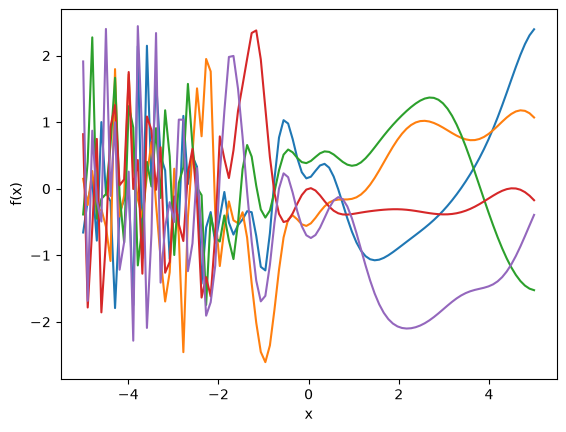

In [93]:
samples_1d = np.random.multivariate_normal(mean, cov, size = 5)

fig, ax = plt.subplots(1, 1)
ax.plot(x, samples_1d.T)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")

In [94]:
# 2D case
x = np.linspace(-2, 2, 50)
y = np.linspace(-2, 2, 50)
X, Y = np.meshgrid(x, y)
xy = np.column_stack([X.ravel(), Y.ravel()]) # XY, 2

mean = m_gibbs(xy[:, 0]) # XY
cov = gram_matrix_gibbs(l, xy)
print(mean.shape)
print(cov.shape)

(2500,)
(2500, 2500)


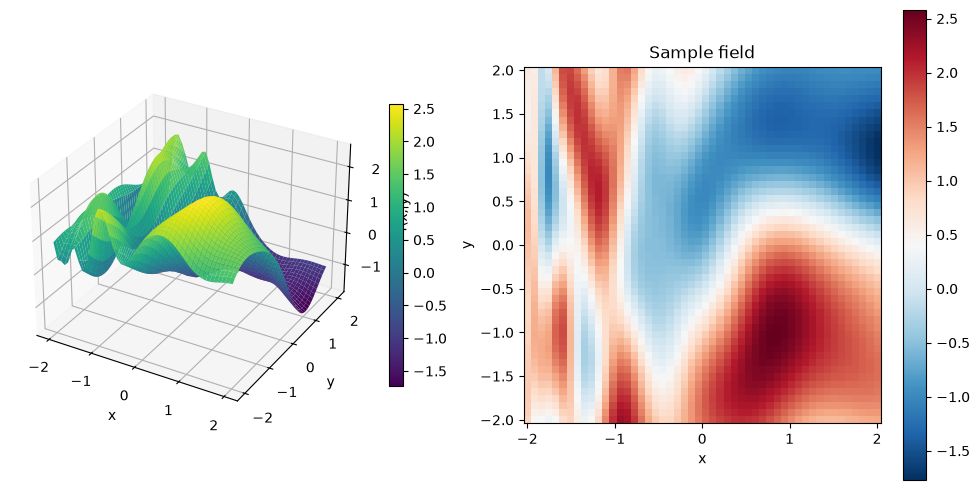

In [95]:
samples_2d = np.random.multivariate_normal(mean, cov).reshape(X.shape)

fig = plt.figure(figsize = (10, 5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surface = ax1.plot_surface(X, Y, samples_2d, cmap="viridis")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("f(x, y)")
fig.colorbar(surface, ax=ax1, shrink=0.6)

ax2 = fig.add_subplot(1, 2, 2)
im = ax2.pcolormesh(
    X, Y, samples_2d,
    shading="auto",
    cmap="RdBu_r",
)
ax2.set_aspect("equal")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Sample field")
fig.colorbar(im, ax=ax2)

fig.tight_layout()

## Question 10

Using the SE kernel, $k(x, x') = \exp ( -b(x - x')^2 )$ and Gaussian density, $\mu(x) = \sqrt{2a / \pi} \exp ( -2ax^2 )$, we can derive the following analytic eigenvalues and eigenfunctions,

\begin{align*}
    \lambda_k &= \sqrt{\frac{2a}{A}} B^k,\\
    \phi_k(x) &= \exp\left(-(c-a) x^2\right) H_k(\sqrt{2c}x),
\end{align*}

where $c = \sqrt{a^2 + 2ab}$, $A = a + b + c$ and $B = b/A$. Here, we use $a = b = 1 \implies c = \sqrt{3}, A = 2 + \sqrt{3}, B = 1/(2 + \sqrt{3})$.


In [96]:
a = 1
b = 1
c = np.sqrt(a**2 + 2 * a * b)
A = a + b + c
B = b / A

k = np.arange(10)
lambdas = np.sqrt(2 * a/A) * B ** k

Text(0.5, 1.0, 'Eigenfunctions')

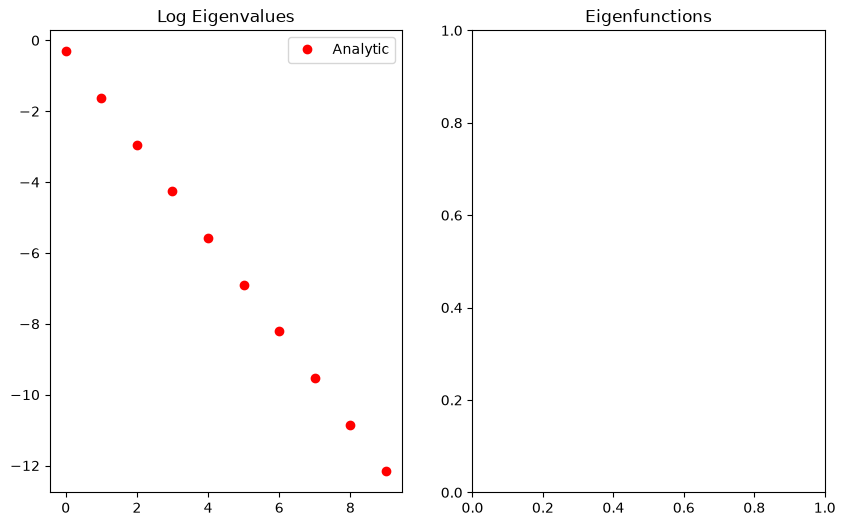

In [97]:
fig, ax = plt.subplots(1, 2, figsize = (10, 6))
ax[0].plot(k, np.log(lambdas), 'ro', label = "Analytic")
ax[0].legend(loc = "upper right")
ax[0].set_title("Log Eigenvalues")


ax[1].set_title("Eigenfunctions")